In [1]:
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_TELEMETRY", "true")   # nada sale a internet salvo Databricks si se configura
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))   # los notebooks importan de src/, nunca al revés

import numpy as np
import pandas as pd
pd.set_option("display.width", 200, "display.max_columns", 40)

# 07 · Validación e interpretación — la prueba se abre **una sola vez**

1. Primero se **congelan** todas las decisiones (modelo, parámetros, calibración, umbral) con datos de entrenamiento.
2. Después se abre la prueba, se mide y **no se cambia nada**.

In [2]:
import json
import joblib
from proyecto.config import GROUP_COL, TARGET, MIN_PRECISION, REPORTS_DIR
from proyecto.data.split import group_cv
from proyecto.models.train import build_pipeline, candidates, evaluate_folds, split_xy, summarize
from proyecto.tracking.mlflow_utils import configure_mlflow, log_run, set_experiment

train = joblib.load(ROOT / "data" / "processed" / "train.joblib")
X, y = split_xy(train)
cv = group_cv(5)   # los MISMOS 5 pliegues por cliente para todo (semilla 42)
donde = configure_mlflow()
print(f"entrenamiento: {len(train):,} créditos · mora {y.mean():.1%} · MLflow: {donde}")

entrenamiento: 36,872 créditos · mora 15.8% · MLflow: local


In [3]:
from datetime import datetime
from sklearn.model_selection import GroupShuffleSplit
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from proyecto.models.train import ShortTermRule, oof_predictions, threshold_for_precision, metrics_at_threshold
from proyecto.models.tuning import MODELS, bootstrap_metric_ci, bootstrap_metric_difference, recall_at_fixed_threshold, precision_at_fixed_threshold
IDEAS = tuple(json.loads((REPORTS_DIR / "04_features_finales.json").read_text())["ideas"])
eleccion = json.loads((REPORTS_DIR / "06_eleccion.json").read_text())
make = MODELS[eleccion["modelo"]][1]
eleccion

{'modelo': 'lightgbm',
 'parametros': {'n_estimators': 300,
  'learning_rate': 0.03,
  'num_leaves': 15,
  'min_child_samples': 100,
  'subsample': 0.8,
  'colsample_bytree': 0.8,
  'reg_lambda': 1.0},
 'origen': 'partida'}

## 1. Calibración — con los clientes reservados (no con la prueba)

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
a, r = next(gss.split(X, y, groups=X[GROUP_COL]))
crudo = build_pipeline(make(eleccion["parametros"]), ideas=IDEAS).fit(X.iloc[a], y[a])
p_crudo = crudo.predict_proba(X.iloc[r])[:, 1]
splits = list(group_cv(5).split(X.iloc[a], y[a], groups=X.iloc[a][GROUP_COL]))
cal = CalibratedClassifierCV(build_pipeline(make(eleccion["parametros"]), ideas=IDEAS), method="isotonic", cv=splits).fit(X.iloc[a], y[a])
p_cal = cal.predict_proba(X.iloc[r])[:, 1]
calib = pd.DataFrame({"sin calibrar": [brier_score_loss(y[r], p_crudo), log_loss(y[r], p_crudo), p_crudo.mean()],
                      "isotónica": [brier_score_loss(y[r], p_cal), log_loss(y[r], p_cal), p_cal.mean()]},
                     index=["Brier", "log loss", "probabilidad media"])
calib.loc["tasa real"] = y[r].mean()
calibrar = bool(calib.loc["Brier", "isotónica"] < calib.loc["Brier", "sin calibrar"] - 0.0005)
frac, media = calibration_curve(y[r], p_crudo, n_bins=8, strategy="quantile")
print(pd.DataFrame({"probabilidad predicha": media, "mora observada": frac}).round(3).to_string(index=False))
print("¿calibrar?", calibrar)
calib.round(4)

 probabilidad predicha  mora observada
                 0.112           0.150
                 0.133           0.152
                 0.143           0.143
                 0.150           0.149
                 0.159           0.162
                 0.169           0.165
                 0.184           0.158
                 0.219           0.181
¿calibrar? False


,sin calibrar,isotónica
Brier,0.1332,0.1328
log loss,0.4373,0.4357
probabilidad media,0.1587,0.1585
tasa real,0.1576,0.1576


## 2. Umbral — con predicciones fuera de pliegue de TODO el entrenamiento

In [5]:
final_pipe = build_pipeline(make(eleccion["parametros"]), ideas=IDEAS)
oof_final, _, _ = oof_predictions(final_pipe, X, y, cv)
umbral = threshold_for_precision(y, oof_final)
oof_regla = ShortTermRule().fit(X, y).predict_proba(X)[:, 1]
umbral_regla = threshold_for_precision(y, oof_regla)
print(f"umbral del modelo: {umbral:.4f} ->", {k: round(v, 3) for k, v in metrics_at_threshold(y, oof_final, umbral).items()})
print(f"umbral de la regla (1/plazo): {umbral_regla:.4f} (plazo ≤ {1 / umbral_regla:.0f} meses) ->",
      {k: round(v, 3) for k, v in metrics_at_threshold(y, oof_regla, umbral_regla).items()})

umbral del modelo: 0.3010 -> {'precision': 0.2, 'recall': 0.001, 'flag_rate': 0.001, 'balanced_accuracy': 0.5, 'f1': 0.002}
umbral de la regla (1/plazo): 0.1667 (plazo ≤ 6 meses) -> {'precision': 0.207, 'recall': 0.117, 'flag_rate': 0.089, 'balanced_accuracy': 0.516, 'f1': 0.149}


In [6]:
DECISIONES = {
    "modelo_final": eleccion["modelo"],
    "parametros": eleccion["parametros"], "origen_parametros": eleccion["origen"],
    "variables": list(IDEAS) or "referencia (12 variables conocidas al aprobar)",
    "calibrar": calibrar,
    "metrica_principal": f"recall de mora_30 con el umbral fijo elegido para precisión ≥ {MIN_PRECISION:.0%} (en validación)",
    "regla_de_decision": f"priorizar revisión si probabilidad ≥ {umbral:.4f}",
    "umbral": umbral, "baseline": "regla del plazo corto", "umbral_baseline": umbral_regla,
    "congeladas_en": datetime.now().isoformat(timespec="seconds"),
}
(REPORTS_DIR / "07_decisiones_congeladas.json").write_text(json.dumps(DECISIONES, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
DECISIONES

{'modelo_final': 'lightgbm',
 'parametros': {'n_estimators': 300,
  'learning_rate': 0.03,
  'num_leaves': 15,
  'min_child_samples': 100,
  'subsample': 0.8,
  'colsample_bytree': 0.8,
  'reg_lambda': 1.0},
 'origen_parametros': 'partida',
 'variables': 'referencia (12 variables conocidas al aprobar)',
 'calibrar': False,
 'metrica_principal': 'recall de mora_30 con el umbral fijo elegido para precisión ≥ 20% (en validación)',
 'regla_de_decision': 'priorizar revisión si probabilidad ≥ 0.3010',
 'umbral': 0.3009887899643487,
 'baseline': 'regla del plazo corto',
 'umbral_baseline': 0.16666666666666666,
 'congeladas_en': '2026-10-31T11:39:38'}

## 3. Modelo final con todo el entrenamiento

In [7]:
modelo_final = build_pipeline(make(eleccion["parametros"]), ideas=IDEAS)
if calibrar:
    modelo_final = CalibratedClassifierCV(modelo_final, method="isotonic", cv=list(cv.split(X, y, groups=X[GROUP_COL])))
modelo_final.fit(X, y)
joblib.dump(modelo_final, ROOT / "models" / "final_pipeline.joblib")
print(type(modelo_final).__name__, "entrenado con", len(X), "créditos")

Pipeline entrenado con 36872 créditos


## 4. Abrir la prueba — una sola vez

In [8]:
marca = REPORTS_DIR / "prueba_abierta.txt"
test = joblib.load(ROOT / "data" / "processed" / "test.joblib")
previo = marca.read_text(encoding="utf-8") if marca.exists() else ""
marca.write_text(previo + f"Prueba abierta el {datetime.now().isoformat(timespec='seconds')} con las decisiones de 07_decisiones_congeladas.json\n", encoding="utf-8")
print(marca.read_text(encoding="utf-8"))   # cada apertura queda registrada; si hay más de una, se declara en el reporte
Xt, yt = split_xy(test)
gt = Xt[GROUP_COL]
p_test = modelo_final.predict_proba(Xt)[:, 1]
p_regla = ShortTermRule().fit(X, y).predict_proba(Xt)[:, 1]
print(f"prueba: {len(test):,} créditos de {gt.nunique():,} clientes · mora real {yt.mean():.1%}")

Prueba abierta el 2026-10-30T21:35:38 con las decisiones de 07_decisiones_congeladas.json
Prueba abierta el 2026-10-30T21:37:46 con las decisiones de 07_decisiones_congeladas.json
Prueba abierta el 2026-10-31T11:39:38 con las decisiones de 07_decisiones_congeladas.json

prueba: 9,178 créditos de 6,932 clientes · mora real 16.3%


In [9]:
def ic(fn, p):
    v, lo, hi = bootstrap_metric_ci(yt, p, gt, fn, n_boot=1000)
    return v, lo, hi

rec_m, rec_r = recall_at_fixed_threshold(umbral), recall_at_fixed_threshold(umbral_regla)
pre_m, pre_r = precision_at_fixed_threshold(umbral), precision_at_fixed_threshold(umbral_regla)
filas = {
    "recall de mora (métrica principal)": (ic(rec_m, p_test), ic(rec_r, p_regla)),
    "precisión (exigida ≥ 20 %)": (ic(pre_m, p_test), ic(pre_r, p_regla)),
    "PR-AUC": (ic(average_precision_score, p_test), ic(average_precision_score, p_regla)),
    "AUC": (ic(roc_auc_score, p_test), ic(roc_auc_score, p_regla)),
}
tabla = pd.DataFrame({k: {"modelo": f"{m[0]:.3f} [{m[1]:.3f}; {m[2]:.3f}]", "regla del plazo corto": f"{b[0]:.3f} [{b[1]:.3f}; {b[2]:.3f}]"}
                      for k, (m, b) in filas.items()}).T
flag_m, flag_r = (p_test >= umbral).mean(), (p_regla >= umbral_regla).mean()
tabla.loc["% de créditos marcados"] = [f"{flag_m:.1%}", f"{flag_r:.1%}"]
tabla

,modelo,regla del plazo corto
recall de mora (métrica principal),0.000 [0.000; 0.000],0.134 [0.116; 0.151]
precisión (exigida ≥ 20 %),0.000 [0.000; 0.000],0.242 [0.212; 0.271]
PR-AUC,0.193 [0.180; 0.208],0.186 [0.174; 0.198]
AUC,0.544 [0.527; 0.560],0.537 [0.520; 0.553]
% de créditos marcados,0.1%,9.0%


In [10]:
# Diferencias modelo − regla, remuestreando clientes completos (el mismo cliente se remuestrea entero)
idx = np.arange(len(yt))
def recall_pair(rows):
    yy = yt[rows]; return (p_test[rows][yy == 1] >= umbral).mean() - (p_regla[rows][yy == 1] >= umbral_regla).mean()
grupos = pd.Series(idx).groupby(gt.values).apply(lambda s: s.to_numpy()).to_numpy()
rng = np.random.default_rng(42)
boot = [recall_pair(np.concatenate(grupos[rng.integers(0, len(grupos), len(grupos))])) for _ in range(1000)]
dif_rec = (recall_pair(idx), np.percentile(boot, 2.5), np.percentile(boot, 97.5))
dif_pr = bootstrap_metric_difference(yt, p_test, p_regla, gt, average_precision_score, n_boot=1000)
dif_auc = bootstrap_metric_difference(yt, p_test, p_regla, gt, roc_auc_score, n_boot=1000)
difs = pd.DataFrame([dif_rec, dif_pr, dif_auc], index=["recall de mora", "PR-AUC", "AUC"], columns=["modelo − regla", "IC inf", "IC sup"])
difs["¿mejora con confianza?"] = difs["IC inf"] > 0
difs.round(4)

,modelo − regla,IC inf,IC sup,¿mejora con confianza?
recall de mora,-0.1339,-0.1505,-0.1162,False
PR-AUC,0.0068,-0.0008,0.0162,False
AUC,0.0072,-0.0084,0.0243,False


## 5. Errores por segmento y carga de trabajo

In [11]:
seg = Xt.copy(); seg["y"] = yt; seg["marca"] = (p_test >= umbral).astype(int); seg["p"] = p_test
seg["plazo"] = pd.cut(seg["term_months"], [0, 12, 36, 72, 400], labels=["≤ 12 m", "13–36 m", "37–72 m", "> 72 m"])
seg["edad"] = pd.cut(seg["age"], [17, 30, 45, 60, 100], labels=["18–30", "31–45", "46–60", "> 60"])
filas_seg = []
for var in ["plazo", "product", "edad"]:
    for nivel, g in seg.groupby(var, observed=True):
        positivos = g["y"].sum()
        filas_seg.append({"segmento": f"{var} = {nivel}", "créditos": len(g), "mora real": round(g["y"].mean(), 3),
                      "% marcado": round(g["marca"].mean(), 3),
                      "recall": round(g.loc[g["y"] == 1, "marca"].mean(), 3) if positivos else np.nan,
                      "precisión": round(g.loc[g["marca"] == 1, "y"].mean(), 3) if g["marca"].any() else np.nan})
segmentos = pd.DataFrame(filas_seg)
segmentos.to_csv(REPORTS_DIR / "07_errores_por_segmento.csv", index=False)
print(f"carga: el modelo marca {seg['marca'].mean():.1%} de los créditos; la mora real es {yt.mean():.1%}")
segmentos

carga: el modelo marca 0.1% de los créditos; la mora real es 16.3%


,segmento,créditos,mora real,% marcado,recall,precisión
0,plazo = ≤ 12 m,2497,0.194,0.002,0.0,0.0
1,plazo = 13–36 m,3029,0.155,0.000,0.0,NaN
2,plazo = 37–72 m,1696,0.139,0.000,0.0,NaN
3,plazo = > 72 m,1956,0.157,0.000,0.0,NaN
4,product = 117,863,0.163,0.001,0.0,0.0
5,product = 118,1066,0.174,0.003,0.0,0.0
6,product = 120,2635,0.146,0.000,0.0,NaN
7,product = 121,1253,0.182,0.001,0.0,0.0
8,product = 128,834,0.200,0.000,0.0,NaN
9,product = 200,1384,0.152,0.000,0.0,NaN


## 6. Interpretación (SHAP)

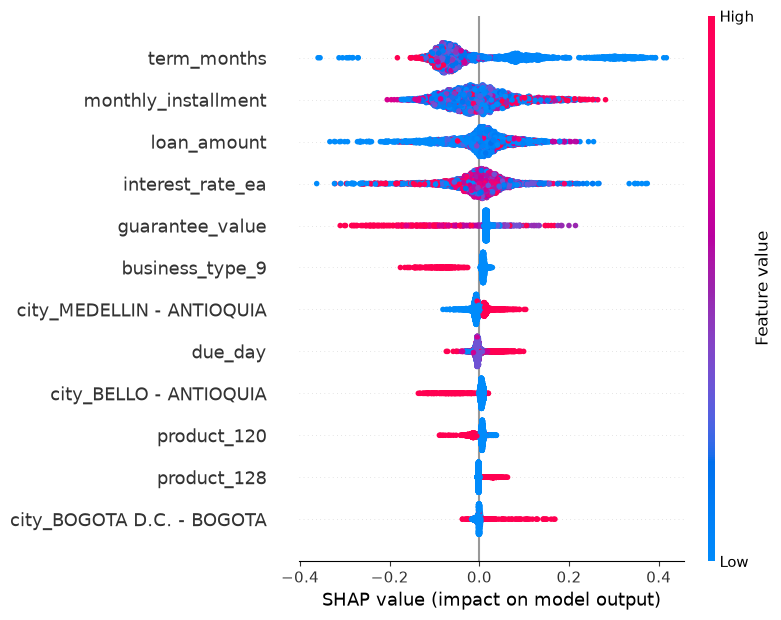

term_months                  0.09372
monthly_installment          0.05487
loan_amount                  0.04859
interest_rate_ea             0.04545
guarantee_value              0.02876
business_type_9              0.01472
city_MEDELLIN - ANTIOQUIA    0.01213
due_day                      0.00997
city_BELLO - ANTIOQUIA       0.00986
product_120                  0.00896
product_128                  0.00445
city_BOGOTA D.C. - BOGOTA    0.00433
dtype: float64

In [12]:
import shap
import matplotlib.pyplot as plt
pipe = modelo_final.calibrated_classifiers_[0].estimator if calibrar else modelo_final
prep, arbol = pipe.named_steps["prep"], pipe.named_steps["model"]
muestra = X.sample(3000, random_state=42)        # se explica con entrenamiento: la prueba ya no decide nada
Z = pd.DataFrame(prep.transform(muestra), columns=prep.get_feature_names_out())
valores = shap.TreeExplainer(arbol).shap_values(Z)
valores = valores[1] if isinstance(valores, list) else valores
imp = pd.Series(np.abs(valores).mean(axis=0), index=Z.columns).sort_values(ascending=False)
imp.round(5).to_csv(REPORTS_DIR / "07_importancia_shap.csv", header=["shap_medio_abs"])
shap.summary_plot(valores, Z, max_display=12, show=False)
plt.tight_layout(); plt.savefig(REPORTS_DIR / "figuras" / "07_shap.png", dpi=120); plt.show()
imp.head(12).round(5)

## 7. Guardar resultados

In [13]:
resultados = {"decisiones": DECISIONES,
              "prueba": {k: {"modelo": list(m), "baseline": list(b)} for k, (m, b) in filas.items()},
              "porcentaje_marcado": {"modelo": float(flag_m), "baseline": float(flag_r)},
              "diferencias_modelo_menos_regla": {k: list(map(float, v[:3])) for k, v in difs.iterrows()},
              "calibracion_reservados": calib.round(5).to_dict(), "mora_real_prueba": float(yt.mean()),
              "n_prueba": int(len(yt)), "clientes_prueba": int(gt.nunique())}
(REPORTS_DIR / "07_metricas_test.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("guardado reports/07_metricas_test.json")

guardado reports/07_metricas_test.json
